In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\LENOVO\Desktop\csv_datasheets\online_retail_combined.csv")

Cleaning Data

In [3]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [4]:
df = df.dropna(subset = ['Customer ID'])
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Customer ID'] =df['Customer ID'].astype(int)

In [5]:
df['Total Price'] = df['Quantity']*df['Price']
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')

Making Graph Chart

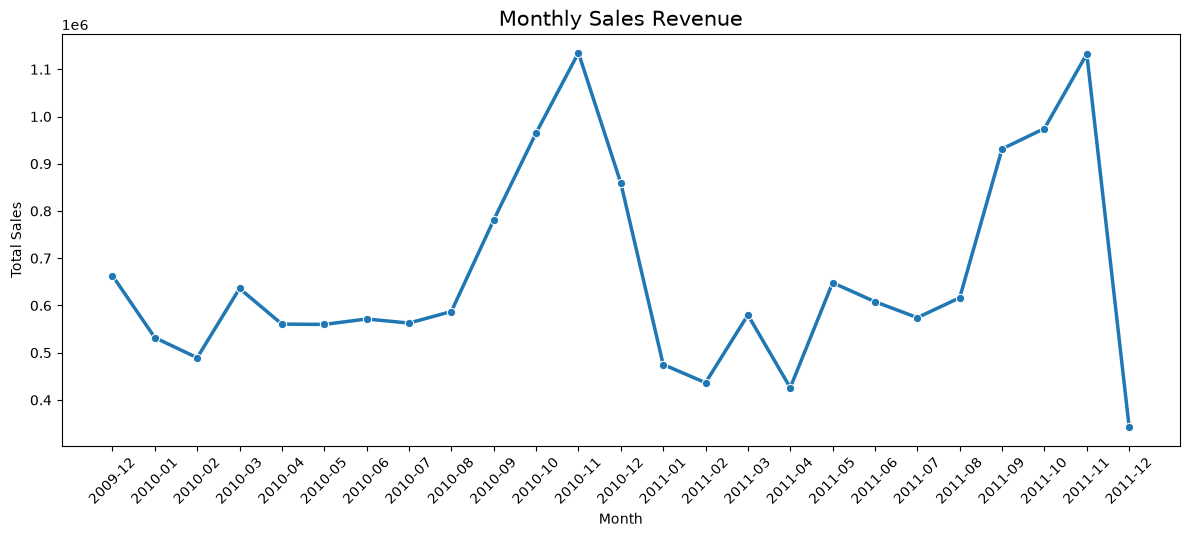

In [6]:
Monthly_Sales = df.groupby('YearMonth')['Total Price'].sum().reset_index()
Monthly_Sales['YearMonth'] = Monthly_Sales['YearMonth'].astype(str)

plt.figure(figsize=(12,5))
sns.lineplot(data=Monthly_Sales,x='YearMonth',y='Total Price', linewidth=2.5, marker='o')
plt.tight_layout()
plt.title('Monthly Sales Revenue' , fontsize = 15)
plt.xlabel("Month" , fontsize = 10)
plt.ylabel('Total Sales' )
plt.xticks(rotation=45)
plt.show()

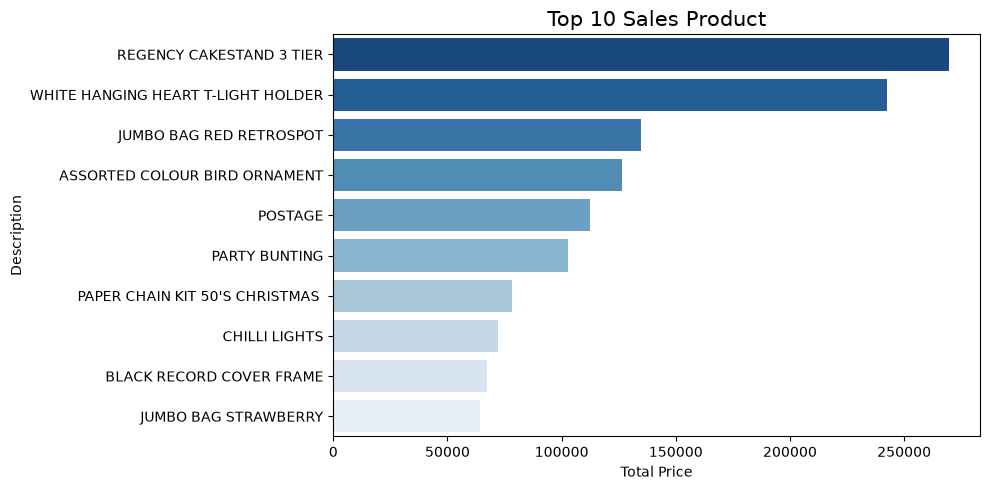

In [7]:
top_products = df.groupby('Description')['Total Price'].sum().nlargest(10).reset_index()

plt.figure(figsize = (10,5))
sns.barplot(data=top_products,x='Total Price' , y='Description', hue='Description', palette='Blues_r', legend=False)
plt.title('Top 10 Sales Product' , fontsize = 15)
plt.tight_layout()
plt.show()

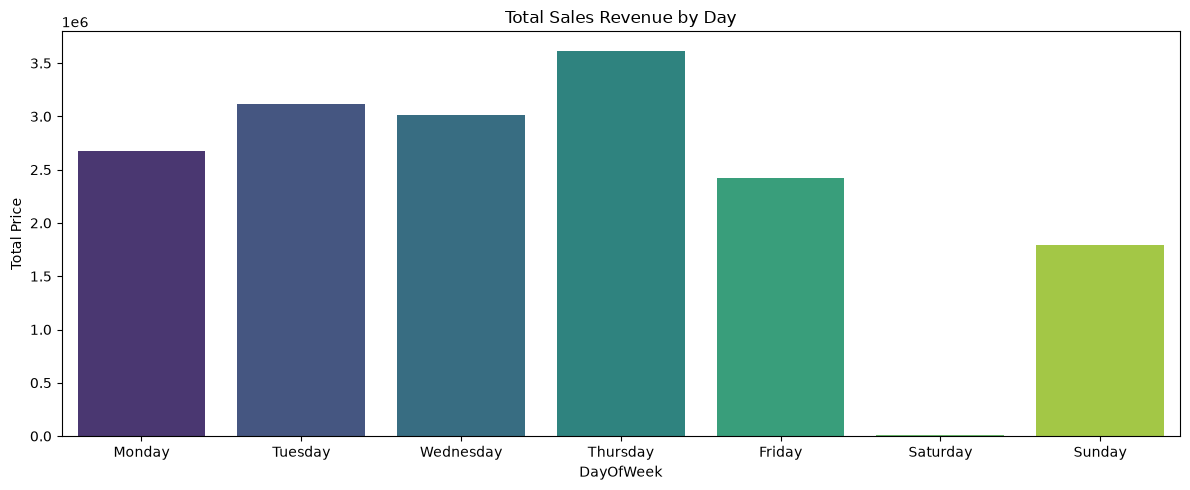

In [8]:
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

daily_sales = (df.groupby(df['InvoiceDate'].dt.day_name().rename('DayOfWeek'))['Total Price']
                 .sum()
                 .reindex(days_order)
                 .reset_index())

plt.figure(figsize=(12, 5))
sns.barplot(data=daily_sales, x='DayOfWeek', y='Total Price',hue='DayOfWeek', palette='viridis', legend=False)
plt.title('Total Sales Revenue by Day')
plt.tight_layout()
plt.show()